# PyTorch on familiar ground

**ISM 6564 — Week 3 companion · the numeric warm-up**

Every other PyTorch notebook this week works on text — tokenizers, sparse
matrices, 636-column rows. This one removes all of that. The dataset here is
the kind you trained on in ISM 6251: a few hundred rows, thirty dense numeric
columns, one label. Nothing about the *data* is new, so all of your attention
can go to the *machine*:

1. **Tensors** — PyTorch's arrays, in two minutes
2. **The data, prepped** — three splits, and why numeric features get scaled
3. **Build** — one linear layer, its weights, then a stack; every parameter counted
4. **Forward** — raw scores, and softmax to turn them into probabilities
5. **Learn** — the loss, the gradients, one *manual* weight update, then the optimizer
6. **Train** — the five-line loop, watched on validation
7. **Evaluate** — the test set, touched once

That is the entire skeleton of deep learning. Everything the other notebooks
add — tokenizers, mini-batches, early stopping, dropout — is a layer on top
of what you build here.

---
## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Reproducibility: fix every source of randomness we are about to use.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"torch {torch.__version__}")

torch 2.11.0


---
## Part 1 — Tensors: PyTorch's arrays

A **tensor** is PyTorch's version of a numpy array — same shapes, same
indexing, same arithmetic. PyTorch has its own array type because tensors can
do two things numpy arrays cannot: live on a GPU, and **remember the
arithmetic done to them**, which is what makes automatic gradients possible
in Part 5.

In [2]:
t = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])

print("shape :", t.shape)            # like arr.shape
print("dtype :", t.dtype)            # like arr.dtype  (float32 by default)
print("t + t :") ; print(t + t)      # elementwise, like numpy

arr = np.array([1.0, 2.0])
print("\nnumpy -> tensor:", torch.tensor(arr, dtype=torch.float32))

shape : torch.Size([2, 3])
dtype : torch.float32
t + t :
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])

numpy -> tensor: tensor([1., 2.])


---
## Part 2 — The data: numbers in, one label out

The Wisconsin breast-cancer dataset ships with scikit-learn — no download, no
cleaning. Each row is one tumor described by **30 numeric measurements**
(radius, texture, symmetry, each summarized a few ways); the label says
whether it proved **malignant (0)** or **benign (1)**. Rows × numeric columns
→ one class per row: exactly the shape you know from ISM 6251.

In [3]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = data.data                      # (569, 30) measurements
y = data.target                    # (569,)    0 = malignant, 1 = benign

print(f"{X.shape[0]} rows x {X.shape[1]} numeric columns")
print(f"labels: {dict(zip(data.target_names, np.bincount(y)))}\n")
pd.DataFrame(X, columns=data.feature_names).iloc[:3, :4]   # a peek

569 rows x 30 numeric columns
labels: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}



,mean radius,mean texture,mean perimeter,mean area
0,17.99,10.38,122.8,1001.0
1,20.57,17.77,132.9,1326.0
2,19.69,21.25,130.0,1203.0


### Prep move 1 — three splits

**Train** is where the model learns. **Validation** is checked during
training, to make decisions. **Test** is touched **once**, at the very end,
for the honest number. Same discipline as all week.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"train {len(X_train)}   val {len(X_val)}   test {len(X_test)}")

train 341   val 114   test 114


### Prep move 2 — scale the features (and *see* why)

This one is new for numeric data. Look at the raw columns first: they live on
wildly different scales. Gradient training nudges *every* weight with small
steps of a shared size — when one column ranges to 4,000 and another to 0.2,
the same step is an earthquake in one direction and a rounding error in
another, and training crawls or wobbles.

`StandardScaler` fixes it: every column becomes mean 0, standard deviation 1.
And the rule of the week applies — **the scaler has a `.fit()`, so it learns
its means and deviations from the training split only.**

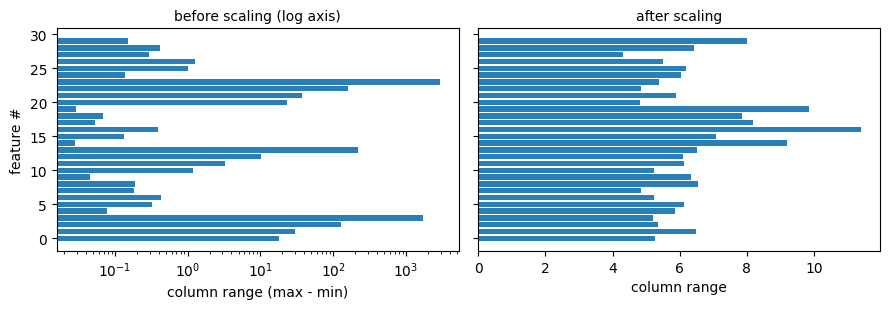

after scaling: column means ~0 (-0.000), sd ~1 (1.000)


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)          # learns mean/sd from TRAIN only
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)             # same scaling, no re-learning
X_test_s  = scaler.transform(X_test)

# See the problem and the fix, side by side: the range of every column.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, M, title in [(axes[0], X_train, "before scaling (log axis)"),
                     (axes[1], X_train_s, "after scaling")]:
    ax.barh(range(30), M.max(axis=0) - M.min(axis=0), color="#2980b9")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("feature #" if ax is axes[0] else "")
axes[0].set_xscale("log")
axes[0].set_xlabel("column range (max - min)"); axes[1].set_xlabel("column range")
plt.tight_layout(); plt.show()

print(f"after scaling: column means ~0 ({X_train_s.mean():.3f}), sd ~1 ({X_train_s.std():.3f})")

Left: column ranges spread across **five orders of magnitude** (note the log
axis). Right: after scaling, every column plays on the same field.

Last prep step — hand it all to PyTorch. Two dtype rules to memorize:
**features are `float32`**, **class labels are `int64`** (torch calls it
`long`; the loss function in Part 5 insists).

In [6]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t   = torch.tensor(X_val_s,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t   = torch.tensor(y_val,   dtype=torch.long)

print(f"X_train_t {tuple(X_train_t.shape)}  {X_train_t.dtype}")
print(f"y_train_t {tuple(y_train_t.shape)}  {y_train_t.dtype}")

X_train_t (341, 30)  torch.float32
y_train_t (341,)  torch.int64


---
## Part 3 — Build: one layer, then a stack

The atom of every neural network is **`nn.Linear`** — a layer of weighted
sums. `nn.Linear(30, 16)` makes sixteen outputs, each one a weighted sum of
all thirty inputs plus a bias: the same arithmetic as logistic regression,
sixteen times over.

A layer *owns its numbers*, and you can look at them:

In [7]:
torch.manual_seed(SEED)            # so your random layer matches ours

layer = nn.Linear(30, 16)          # 30 measurements in -> 16 numbers out

print("weight:", tuple(layer.weight.shape), "  <- one row of 30 weights per output")
print("bias  :", tuple(layer.bias.shape),   "  <- one bias per output")
print("\nfirst output's first 5 weights (random, for now):")
print(layer.weight[0, :5].data)

weight: (16, 30)   <- one row of 30 weights per output
bias  : (16,)   <- one bias per output

first output's first 5 weights (random, for now):
tensor([ 0.1396,  0.1515, -0.0428,  0.1677, -0.0400])


Those weights start as small random numbers — **training's whole job is to
change them.**

Two more pieces and the model is complete:

- **`nn.ReLU()`** — the kink: negatives become zero, positives pass. Without
  a nonlinearity between them, two weighted sums in a row collapse into one
  weighted sum, and the second layer would buy nothing.
- **a second `nn.Linear(16, 2)`** — one score per class.

`nn.Sequential` means "run these in order":

In [8]:
torch.manual_seed(SEED)            # rebuild from the same starting point

model = nn.Sequential(
    nn.Linear(30, 16),             # 30 measurements -> 16 hidden units
    nn.ReLU(),                     # the kink (owns no numbers)
    nn.Linear(16, 2),              # 16 hidden units -> 2 class scores
)
print(model)

# "Parameter" = a number training may change. Count every one:
total = sum(p.numel() for p in model.parameters())
print(f"\nparameters: {total}   check: 30*16 + 16  +  16*2 + 2  =  {30*16 + 16 + 16*2 + 2}")

Sequential(
  (0): Linear(in_features=30, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=2, bias=True)
)

parameters: 530   check: 30*16 + 16  +  16*2 + 2  =  530


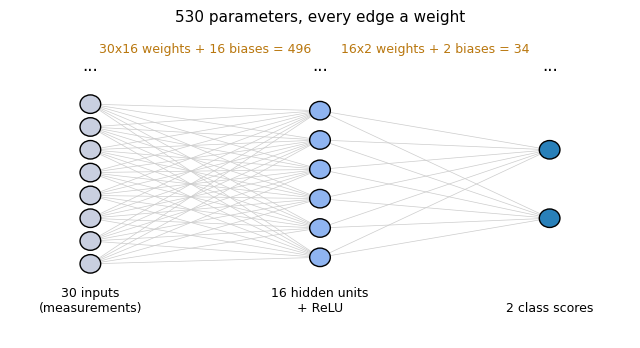

In [9]:
# The same model, drawn. (Diagram only -- nothing here affects training.)
fig, ax = plt.subplots(figsize=(8, 4))
cols = {"in": (0, 8, "#C9CFE0", "30 inputs\n(measurements)"),
        "hid": (1, 6, "#8FB4F0", "16 hidden units\n+ ReLU"),
        "out": (2, 2, "#2980b9", "2 class scores")}
pos = {}
for key, (x, n, color, label) in cols.items():
    ys = np.linspace(0, 1, n + 2)[1:-1]
    pos[key] = [(x, yy) for yy in ys]
    for xx, yy in pos[key]:
        ax.add_patch(plt.Circle((xx, yy), 0.045, color=color, ec="k", zorder=3))
    ax.text(x, -0.12, label, ha="center", fontsize=9)
    ax.text(x, 1.05, "...", ha="center", fontsize=12)
for a in pos["in"]:
    for b in pos["hid"]:
        ax.plot([a[0], b[0]], [a[1], b[1]], color="0.8", lw=0.5, zorder=1)
for a in pos["hid"]:
    for b in pos["out"]:
        ax.plot([a[0], b[0]], [a[1], b[1]], color="0.8", lw=0.5, zorder=1)
ax.text(0.5, 1.14, "30x16 weights + 16 biases = 496", ha="center", fontsize=9, color="#b9770e")
ax.text(1.5, 1.14, "16x2 weights + 2 biases = 34", ha="center", fontsize=9, color="#b9770e")
ax.set_xlim(-0.35, 2.35); ax.set_ylim(-0.25, 1.25); ax.axis("off")
ax.set_title("530 parameters, every edge a weight", fontsize=11)
plt.show()

---
## Part 4 — Forward: scores, then probabilities

The model already *runs* — its 530 random numbers just make it run badly.
Push three rows through and look at what comes out.

The two raw outputs per row are called **logits**: bigger means "more likely
this class", but they are not probabilities — they can be negative and do not
sum to 1. **`softmax`** converts each row of logits into probabilities.
(With a single output you would use its one-output cousin, the **sigmoid**;
softmax is the multi-class version, and works fine for 2 classes.)

In [10]:
logits = model(X_train_t[:3])              # 3 rows in -> 3 rows of 2 scores
probs  = torch.softmax(logits, dim=1)      # each row -> probabilities

print("logits:") ; print(logits.data)
print("\nprobabilities (rows sum to 1):") ; print(probs.data)
print("\npredicted:", [str(data.target_names[i]) for i in probs.argmax(dim=1)])
print("actual   :", [str(data.target_names[i]) for i in y_train[:3]])

logits:
tensor([[ 0.2580,  0.1593],
        [ 0.0648,  0.1294],
        [-0.1360, -0.0539]])

probabilities (rows sum to 1):
tensor([[0.5247, 0.4753],
        [0.4839, 0.5161],
        [0.4795, 0.5205]])

predicted: ['malignant', 'benign', 'benign']
actual   : ['benign', 'malignant', 'benign']


Roughly 50/50 everywhere — an untrained model is a coin flip. Parts 5 and 6
turn those 530 random numbers into informed ones.

---
## Part 5 — Learn: loss → gradients → one manual update → the optimizer

**The loss** is one number saying how wrong the model is right now.
`CrossEntropyLoss` is *the* loss for classification. Two things it insists
on: give it raw **logits** (it applies softmax itself), and integer class
labels (our `long` tensors) — not one-hot columns.

In [11]:
loss_fn = nn.CrossEntropyLoss()

loss = loss_fn(model(X_train_t), y_train_t)
print(f"untrained loss: {loss.item():.4f}")
print(f"coin-flip benchmark ln(2) = {np.log(2):.4f}")

untrained loss: 0.6508
coin-flip benchmark ln(2) = 0.6931


A model that spreads its probability exactly 50/50 scores ln(2) ≈ 0.693 —
the coin-flip benchmark. Ours starts a whisker below it: its random weights
already produce nearly-even probabilities. **Training means pushing this
number down.**

**The gradients** answer: for each of the 530 parameters, does nudging it up
or down reduce the loss, and how strongly? One call computes all 530 —
because tensors remember their arithmetic, `loss.backward()` walks it
backwards and fills in every slope.

**One manual update** — do the optimizer's job yourself, once, so it is
never a mystery: step every parameter a little *against* its gradient.

In [12]:
loss = loss_fn(model(X_train_t), y_train_t)   # measure
loss.backward()                               # gradients for all 530 numbers

print(f"loss before: {loss.item():.4f}")
print(f"a gradient landed on every parameter, e.g. first layer weights: "
      f"{tuple(model[0].weight.grad.shape)}")

with torch.no_grad():                         # updating is not learning math
    for p in model.parameters():
        p -= 0.1 * p.grad                     # step AGAINST the slope
        p.grad = None                         # clear it (gradients accumulate)

print(f"loss after : {loss_fn(model(X_train_t), y_train_t).item():.4f}   <- one step of learning, by hand")

loss before: 0.6508
a gradient landed on every parameter, e.g. first layer weights: (16, 30)
loss after : 0.5983   <- one step of learning, by hand


That subtraction — *parameter minus step-size times gradient* — **is**
learning. The **optimizer** does exactly this for you, with smarter
per-parameter step sizes; `Adam` is the standard choice and we accept all of
its defaults (its most important one: the learning rate, `lr=0.001`).

---
## Part 6 — Train: the five-line loop

Rebuild the model fresh (our manual fiddling touched it), then repeat the
heartbeat: clear the gradients (they accumulate), forward, loss, backward,
step. This dataset is small enough to process whole per epoch — no batching
needed yet. After each epoch we score the **validation** set — data the model
is *not* learning from — because training loss alone cannot tell us whether
the model is genuinely getting better or just memorizing.

In [13]:
torch.manual_seed(SEED)                          # fresh model, same start as ours
model = nn.Sequential(
    nn.Linear(30, 16), nn.ReLU(), nn.Linear(16, 2))
loss_fn   = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())  # all defaults

def accuracy(model, X, y):
    """Fraction correct -- measuring only, no learning."""
    model.eval()                             # evaluation mode
    with torch.no_grad():                    # no gradient bookkeeping
        predicted = model(X).argmax(dim=1)   # biggest score = predicted class
    model.train()                            # back to training mode
    return (predicted == y).float().mean().item()

history = []
for epoch in range(1, 101):
    optimizer.zero_grad()                    # 1. clear old gradients
    predictions = model(X_train_t)           # 2. forward pass
    loss = loss_fn(predictions, y_train_t)   # 3. measure the error
    loss.backward()                          # 4. compute all 530 gradients
    optimizer.step()                         # 5. nudge every parameter

    val_acc = accuracy(model, X_val_t, y_val_t)
    history.append((epoch, loss.item(), val_acc))
    if epoch == 1 or epoch % 20 == 0:
        print(f"epoch {epoch:3d}   loss {loss.item():.4f}   val accuracy {val_acc:.4f}")

epoch   1   loss 0.6508   val accuracy 0.6579
epoch  20   loss 0.4595   val accuracy 0.9561
epoch  40   loss 0.3245   val accuracy 0.9649
epoch  60   loss 0.2383   val accuracy 0.9649
epoch  80   loss 0.1852   val accuracy 0.9737
epoch 100   loss 0.1510   val accuracy 0.9737


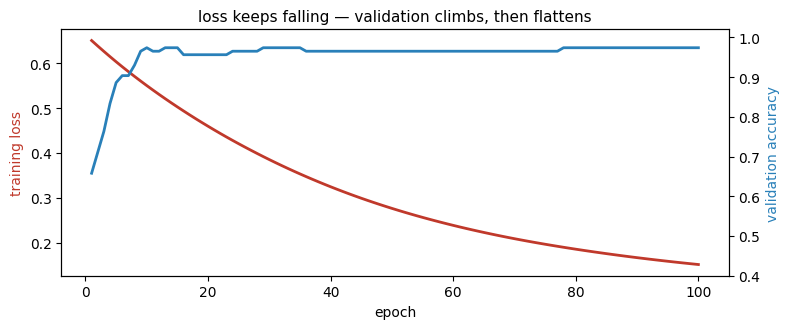

In [14]:
# The picture every training run should produce: loss down, validation up-then-flat.
h = np.array(history)
fig, ax1 = plt.subplots(figsize=(8, 3.4))
ax1.plot(h[:, 0], h[:, 1], color="#c0392b", lw=2, label="training loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss", color="#c0392b")
ax2 = ax1.twinx()
ax2.plot(h[:, 0], h[:, 2], color="#2980b9", lw=2, label="validation accuracy")
ax2.set_ylabel("validation accuracy", color="#2980b9"); ax2.set_ylim(0.4, 1.02)
ax1.set_title("loss keeps falling — validation climbs, then flattens", fontsize=11)
plt.tight_layout(); plt.show()

Read it the way Week 3 taught you: the red curve falls for as long as you let
it — memorizing is cheap. The blue curve is the honest one: it climbs, then
flattens. Past the plateau, extra epochs polish the model's memory of the
training set, not its judgement. (Stopping *automatically* at the plateau is
early stopping — one of the layers the other notebooks add.)

---
## Part 7 — Evaluate: the test set, once

Validation helped us watch training, so its score is slightly flattered. The
test set has been touched by nothing. Spend it once — this is the number you
would report.

TEST accuracy: 0.9474


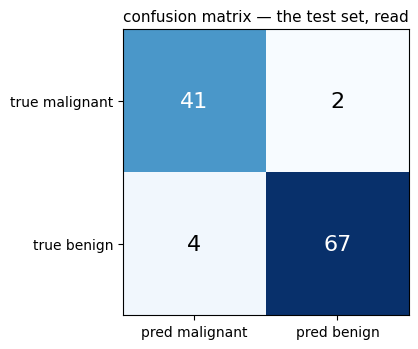

In [15]:
from sklearn.metrics import confusion_matrix

model.eval()
with torch.no_grad():
    test_pred = model(X_test_t).argmax(dim=1).numpy()

print(f"TEST accuracy: {(test_pred == y_test).mean():.4f}")

cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xticks([0, 1], [f"pred {n}" for n in data.target_names])
ax.set_yticks([0, 1], [f"true {n}" for n in data.target_names])
ax.set_title("confusion matrix — the test set, read", fontsize=11)
plt.tight_layout(); plt.show()

Read the matrix, not just the number: the diagonal is correct; each
off-diagonal cell is a specific, nameable mistake — and on a medical dataset
the two mistakes are not equally costly (a missed malignancy is not a false
alarm), which is exactly the judgement no accuracy score makes for you.

---
## Where you now stand

You have run the entire skeleton of deep learning:

| step | what you did | the one rule |
|---|---|---|
| Prep | three splits, scale the features | anything with a `.fit()` learns from **train only** |
| Build | `Linear → ReLU → Linear` | count your parameters (530 here) |
| Learn | loss → gradients → step against the slope | you did the optimizer's job by hand, once |
| Train | the five-line loop | watch **validation**, not training loss |
| Evaluate | test, once | the honest number comes last |

Every other PyTorch notebook this week is this skeleton plus layers:

- **`ism6564-week03-pytorch-intro.ipynb`** — the same skeleton on *text*,
  built twice (sklearn ↔ PyTorch) so the two toolkits map onto each other.
- **`ism6564-week03-pytorch-step-by-step.ipynb`** — every piece opened up
  slowly, then extended: mini-batches (`DataLoader`), early stopping,
  dropout, class weights, even swapping the tokenizer.

The skeleton never changes. Week 4 keeps it too — and only swaps what is
inside the model.